# Assignment 9 - Financial Blockchain Capstone: African Remittances Payment Prototype


- **Problem:** sending money home is slow and expensive. The World Bank puts the global average cost at about 6.4% of the amount sent, and Sub-Saharan Africa is usually the most expensive region. Money often passes through several banks or operators and can take days.
- **Corridor:** a worker in South Africa sends rand to family at home. The sender pays in rand and the recipient receives rand.
- **Idea:** use a stablecoin as the rail between the two ends. Rand is only handled at the on-ramp and off-ramp. In the middle, value moves on a shared ledger that anyone can check.
- **The financial rule that holds it together:** every mZAR is backed by 1 ZAR in a vault (the Reserve account). Rand goes in before mZAR is created, and mZAR is burned before rand goes out.
- **Not a production product.** It shows the ledger, custody and verification layers that such a product rests on.

```

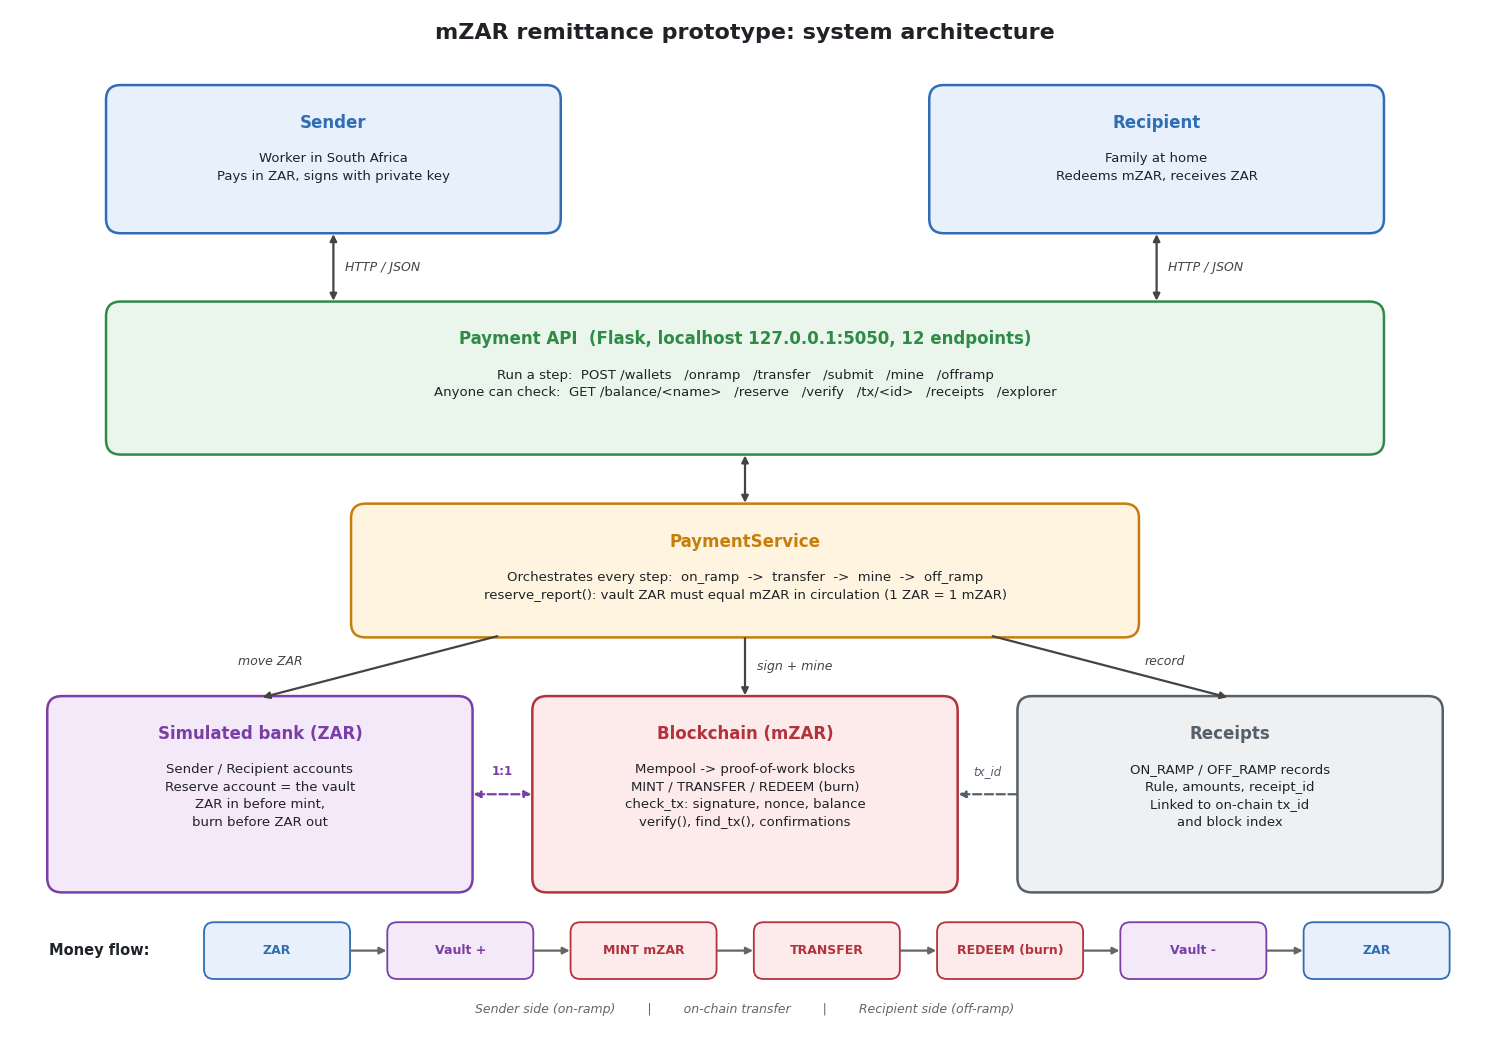

Saved architecture.png


In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Colours: one per layer
C_USER = "#E8F1FB"; E_USER = "#2F6DB5"
C_API = "#EAF6EC";  E_API = "#2E8B47"
C_SVC = "#FFF4E0";  E_SVC = "#C77D0A"
C_BANK = "#F3E9F9"; E_BANK = "#7A3FA6"
C_CHAIN = "#FDEBEC"; E_CHAIN = "#B3323C"
C_RCPT = "#EEF0F2"; E_RCPT = "#55606B"
TEXT = "#1F2328"


def box(ax, x, y, w, h, title, lines, face, edge, title_size=12, line_size=9.5):
    """Rounded box with a bold title and smaller detail lines. (x, y) is the bottom-left corner."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                facecolor=face, edgecolor=edge, linewidth=1.8))
    ax.text(x + w / 2, y + h - 0.28, title, ha="center", va="top",
            fontsize=title_size, fontweight="bold", color=edge)
    ax.text(x + w / 2, y + h - 0.68, "\n".join(lines), ha="center", va="top",
            fontsize=line_size, color=TEXT, linespacing=1.45)


def arrow(ax, start, end, label=None, both=False, dashed=False, colour="#444", offset=(0.12, 0), size=9):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="<|-|>" if both else "-|>", color=colour, lw=1.6,
                                linestyle="--" if dashed else "-", shrinkA=2, shrinkB=2))
    if label:
        mx, my = (start[0] + end[0]) / 2 + offset[0], (start[1] + end[1]) / 2 + offset[1]
        ax.text(mx, my, label, fontsize=size, color=colour, ha="left", va="center", style="italic")


fig, ax = plt.subplots(figsize=(15, 10.5))
ax.set_xlim(0, 15); ax.set_ylim(-0.1, 10.5); ax.axis("off")

ax.text(7.5, 10.2, "mZAR remittance prototype: system architecture", ha="center",
        fontsize=16, fontweight="bold", color=TEXT)

# Layer 1: users
box(ax, 1.0, 8.2, 4.6, 1.5, "Sender", ["Worker in South Africa", "Pays in ZAR, signs with private key"], C_USER, E_USER)
box(ax, 9.4, 8.2, 4.6, 1.5, "Recipient", ["Family at home", "Redeems mZAR, receives ZAR"], C_USER, E_USER)

# Layer 2: API
box(ax, 1.0, 5.9, 13.0, 1.55, "Payment API  (Flask, localhost 127.0.0.1:5050, 12 endpoints)",
    ["Run a step:  POST /wallets   /onramp   /transfer   /submit   /mine   /offramp",
     "Anyone can check:  GET /balance/<name>   /reserve   /verify   /tx/<id>   /receipts   /explorer"],
    C_API, E_API)
arrow(ax, (3.3, 8.2), (3.3, 7.45), "HTTP / JSON", both=True)
arrow(ax, (11.7, 8.2), (11.7, 7.45), "HTTP / JSON", both=True)

# Layer 3: orchestration
box(ax, 3.5, 4.0, 8.0, 1.35, "PaymentService",
    ["Orchestrates every step:  on_ramp  ->  transfer  ->  mine  ->  off_ramp",
     "reserve_report(): vault ZAR must equal mZAR in circulation (1 ZAR = 1 mZAR)"],
    C_SVC, E_SVC)
arrow(ax, (7.5, 5.9), (7.5, 5.35), both=True)

# Layer 4: components
box(ax, 0.4, 1.35, 4.3, 2.0, "Simulated bank (ZAR)",
    ["Sender / Recipient accounts", "Reserve account = the vault", "ZAR in before mint,", "burn before ZAR out"],
    C_BANK, E_BANK)
box(ax, 5.35, 1.35, 4.3, 2.0, "Blockchain (mZAR)",
    ["Mempool -> proof-of-work blocks", "MINT / TRANSFER / REDEEM (burn)", "check_tx: signature, nonce, balance",
     "verify(), find_tx(), confirmations"],
    C_CHAIN, E_CHAIN)
box(ax, 10.3, 1.35, 4.3, 2.0, "Receipts",
    ["ON_RAMP / OFF_RAMP records", "Rule, amounts, receipt_id", "Linked to on-chain tx_id", "and block index"],
    C_RCPT, E_RCPT)
arrow(ax, (5.0, 4.0), (2.55, 3.35), "move ZAR", offset=(-1.45, 0.05))
arrow(ax, (7.5, 4.0), (7.5, 3.35), "sign + mine", offset=(0.12, 0))
arrow(ax, (10.0, 4.0), (12.45, 3.35), "record", offset=(0.35, 0.05))
arrow(ax, (10.3, 2.35), (9.65, 2.35), dashed=True, colour=E_RCPT)
ax.text(9.97, 2.55, "tx_id", fontsize=8.5, ha="center", color=E_RCPT, style="italic")
arrow(ax, (4.7, 2.35), (5.35, 2.35), both=True, dashed=True, colour=E_BANK)
ax.text(5.02, 2.55, "1:1", fontsize=8.5, ha="center", color=E_BANK, fontweight="bold")

# Money flow strip
steps = [("ZAR", C_USER, E_USER), ("Vault +", C_BANK, E_BANK), ("MINT mZAR", C_CHAIN, E_CHAIN),
         ("TRANSFER", C_CHAIN, E_CHAIN), ("REDEEM (burn)", C_CHAIN, E_CHAIN), ("Vault -", C_BANK, E_BANK),
         ("ZAR", C_USER, E_USER)]
ax.text(0.4, 0.725, "Money flow:", fontsize=10.5, fontweight="bold", color=TEXT, va="center")
w, gap, x0 = 1.45, 0.42, 2.0
for i, (label, face, edge) in enumerate(steps):
    x = x0 + i * (w + gap)
    ax.add_patch(FancyBboxPatch((x, 0.45), w, 0.55, boxstyle="round,pad=0.02,rounding_size=0.1",
                                facecolor=face, edgecolor=edge, linewidth=1.3))
    ax.text(x + w / 2, 0.725, label, ha="center", va="center", fontsize=9, color=edge, fontweight="bold")
    if i < len(steps) - 1:
        arrow(ax, (x + w, 0.725), (x + w + gap, 0.725), colour="#666")
ax.text(7.5, 0.08, "Sender side (on-ramp)        |        on-chain transfer        |        Recipient side (off-ramp)",
        ha="center", fontsize=9, color="#666", style="italic")

plt.tight_layout()
fig.savefig("architecture.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved architecture.png")

## Section 1: Settings and helpers

In [2]:
import copy
import hashlib
import json
import logging
import threading
import time
import urllib.error
import urllib.request
from collections import defaultdict

from ecdsa import BadSignatureError, SECP256k1, SigningKey, VerifyingKey
from flask import Flask, Response, jsonify, request
from werkzeug.serving import make_server

COIN = "mZAR"             # the simulated stablecoin
RULE = "1 ZAR = 1 mZAR"   # reserve rule: every mZAR is backed by 1 ZAR held in reserve
DIFFICULTY = 3            # a block hash must start with this many zeros (low, so the demo is fast)
ZERO_HASH = "0" * 64
MIN_CONFIRMATIONS = 1     # blocks a payment must sit under before the off-ramp pays out (inclusion counts as 1)
PORT = 5050               # localhost port for the payment API


def sha256_hex(text):
    """Fingerprint of a piece of text."""
    return hashlib.sha256(str(text).encode()).hexdigest()


def canonical(data):
    """Write data as JSON in a fixed order, so the same data always gives the same fingerprint."""
    return json.dumps(data, sort_keys=True, separators=(",", ":"))


def is_positive_int(value):
    return isinstance(value, int) and not isinstance(value, bool) and value > 0

## Section 2: Wallets 

In [3]:
def make_address(public_key):
    """Address = 'mz' + the first 38 characters of the public key's fingerprint."""
    return "mz" + sha256_hex(public_key)[:38]


def verify_signature(public_key, message, signature):
    """True only if the signature was made by the private key that belongs to this public key."""
    try:
        key = VerifyingKey.from_string(bytes.fromhex(public_key), curve=SECP256k1)
        return key.verify(bytes.fromhex(signature), message.encode(), hashfunc=hashlib.sha256)
    except (BadSignatureError, ValueError, TypeError, AssertionError):
        return False


class Wallet:
    def __init__(self, name):
        self.name = name
        self._key = SigningKey.generate(curve=SECP256k1)      # private key, kept inside
        self.public_key = self._key.get_verifying_key().to_string().hex()
        self.address = make_address(self.public_key)

    def sign(self, message):
        return self._key.sign(message.encode(), hashfunc=hashlib.sha256).hex()

    def info(self):
        """What the API may show: never the private key."""
        return {"name": self.name, "address": self.address, "public_key": self.public_key}

## Section 3: Transactions and the rules that protect them

In [4]:
TX_TYPES = ("MINT", "TRANSFER", "REDEEM")
SIGNED_FIELDS = ("type", "sender", "recipient", "amount", "nonce", "timestamp")


def tx_payload(tx):
    """The fields that are signed and fingerprinted (the signature itself is left out)."""
    return canonical({field: tx[field] for field in SIGNED_FIELDS})


def build_tx(wallet, tx_type, recipient, amount, nonce):
    """Create a transaction, give it an ID and sign it with the wallet's private key."""
    tx = {"type": tx_type, "sender": wallet.address, "recipient": recipient, "amount": amount,
          "nonce": nonce, "timestamp": round(time.time(), 3), "public_key": wallet.public_key}
    tx["tx_id"] = sha256_hex(tx_payload(tx))
    tx["signature"] = wallet.sign(tx_payload(tx))
    return tx


def new_state():
    """Balances and nonces are never typed in. They are rebuilt by replaying transactions."""
    return {"balance": defaultdict(int), "nonce": defaultdict(int), "minted": 0, "burned": 0}


def check_tx(tx, state, reserve_address):
    """Raise ValueError with the reason if the transaction is not acceptable."""
    missing = [f for f in SIGNED_FIELDS + ("public_key", "signature", "tx_id") if f not in tx]
    if missing:
        raise ValueError(f"missing fields: {missing}")
    if tx["type"] not in TX_TYPES:
        raise ValueError(f"unknown type: {tx['type']}")
    if not is_positive_int(tx["amount"]):
        raise ValueError("amount must be a positive whole number")
    if make_address(tx["public_key"]) != tx["sender"]:
        raise ValueError("public key does not match the sender address")
    if sha256_hex(tx_payload(tx)) != tx["tx_id"]:
        raise ValueError("tx_id does not match the contents")
    if not verify_signature(tx["public_key"], tx_payload(tx), tx["signature"]):
        raise ValueError("invalid signature")
    expected = state["nonce"][tx["sender"]]
    if tx["nonce"] != expected:
        raise ValueError(f"bad nonce: expected {expected}, got {tx['nonce']} (replay or wrong order)")
    if tx["type"] == "MINT" and tx["sender"] != reserve_address:
        raise ValueError("only the reserve agent may mint")
    if tx["type"] == "REDEEM" and tx["recipient"] != reserve_address:
        raise ValueError("redeem must be paid to the reserve agent")
    if tx["type"] == "TRANSFER" and tx["recipient"] == tx["sender"]:
        raise ValueError("sender and recipient must differ")
    if tx["type"] != "MINT" and state["balance"][tx["sender"]] < tx["amount"]:
        raise ValueError(f"insufficient balance: has {state['balance'][tx['sender']]} {COIN}, needs {tx['amount']}")


def apply_tx(tx, state):
    """Update balances and supply for one transaction that has passed check_tx."""
    amount, sender = tx["amount"], tx["sender"]
    state["nonce"][sender] += 1
    if tx["type"] == "MINT":
        state["balance"][tx["recipient"]] += amount
        state["minted"] += amount
    elif tx["type"] == "TRANSFER":
        state["balance"][sender] -= amount
        state["balance"][tx["recipient"]] += amount
    else:  # REDEEM burns the coins
        state["balance"][sender] -= amount
        state["burned"] += amount

## Section 4: Blockchain, mining and verification

In [5]:
def block_hash(block):
    """Fingerprint of a block: its position, time, transaction IDs, previous hash and nonce."""
    header = {"index": block["index"], "timestamp": block["timestamp"],
              "tx_ids": [t["tx_id"] for t in block["transactions"]],
              "previous_hash": block["previous_hash"], "nonce": block["nonce"]}
    return sha256_hex(canonical(header))


class Blockchain:
    def __init__(self, reserve_address, difficulty=DIFFICULTY):
        self.reserve_address = reserve_address
        self.difficulty = difficulty
        self.mempool = []     # valid payments waiting to be mined
        self.chain = []
        self._mine([], ZERO_HASH)     # block 0, the genesis block

    def _mine(self, transactions, previous_hash):
        """Proof of work: raise the nonce until the hash starts with enough zeros."""
        block = {"index": len(self.chain), "timestamp": round(time.time(), 3),
                 "transactions": transactions, "previous_hash": previous_hash, "nonce": 0}
        while not block_hash(block).startswith("0" * self.difficulty):
            block["nonce"] += 1
        block["hash"] = block_hash(block)
        self.chain.append(block)
        return block

    def state(self, include_pending=False):
        """Replay the confirmed transactions (and optionally the pending ones)."""
        state = new_state()
        txs = [t for block in self.chain for t in block["transactions"]]
        for tx in txs + (self.mempool if include_pending else []):
            apply_tx(tx, state)
        return state

    def balance(self, address):
        return self.state()["balance"][address]

    def next_nonce(self, address):
        return self.state(include_pending=True)["nonce"][address]

    def add_tx(self, tx):
        """Check a transaction against confirmed and pending state, then queue it."""
        check_tx(tx, self.state(include_pending=True), self.reserve_address)
        self.mempool.append(tx)
        return tx["tx_id"]

    def mine_pending(self):
        """Put every waiting transaction into one new block."""
        if not self.mempool:
            raise ValueError("no pending transactions to mine")
        block = self._mine(list(self.mempool), self.chain[-1]["hash"])
        self.mempool = []
        return block

    def verify(self, chain=None):
        """Re-check every link, hash, proof of work and transaction. Any party can run this."""
        chain = self.chain if chain is None else chain
        problems, state = [], new_state()
        for i, block in enumerate(chain):
            previous = ZERO_HASH if i == 0 else chain[i - 1]["hash"]
            if block["previous_hash"] != previous:
                problems.append(f"block {i}: link to the previous block is broken")
            if block_hash(block) != block["hash"]:
                problems.append(f"block {i}: hash does not match the contents")
            if not block["hash"].startswith("0" * self.difficulty):
                problems.append(f"block {i}: proof of work is missing")
            for tx in block["transactions"]:
                try:
                    check_tx(tx, state, self.reserve_address)
                    apply_tx(tx, state)
                except ValueError as error:
                    problems.append(f"block {i}: {error}")
        return {"valid": not problems, "blocks_checked": len(chain), "problems": problems}

    def find_tx(self, tx_id):
        """Look a transaction up by ID. Confirmations = tip height - block height + 1."""
        for block in self.chain:
            for tx in block["transactions"]:
                if tx["tx_id"] == tx_id:
                    return {"status": "confirmed", "block_index": block["index"],
                            "block_hash": block["hash"],
                            "confirmations": len(self.chain) - block["index"], "transaction": tx}
        for tx in self.mempool:
            if tx["tx_id"] == tx_id:
                return {"status": "pending", "transaction": tx}
        raise KeyError(tx_id)

    def latest_credit_depth(self, address):
        """Confirmations of the newest payment this address received (0 if none)."""
        for block in reversed(self.chain):
            if any(t["recipient"] == address and t["type"] != "REDEEM" for t in block["transactions"]):
                return len(self.chain) - block["index"]
        return 0

## Section 5: Bank money, on-ramp and off-ramp

In [6]:
class PaymentService:
    def __init__(self, difficulty=DIFFICULTY):
        self.wallets = {}                 # name -> Wallet
        self.bank = defaultdict(int)      # name -> ZAR held in the simulated bank
        self.receipts = []
        self.create_wallet("Reserve", 0)
        self.reserve = self.wallets["Reserve"]
        self.chain = Blockchain(self.reserve.address, difficulty)

    def create_wallet(self, name, zar):
        if name in self.wallets:
            raise ValueError(f"wallet '{name}' already exists")
        self.wallets[name] = Wallet(name)
        self.bank[name] = zar
        return {**self.wallets[name].info(), "bank_zar": zar}

    def name_of(self, address):
        return next((n for n, w in self.wallets.items() if w.address == address), address[:10] + "...")

    def move_zar(self, source, destination, amount):
        if not is_positive_int(amount):
            raise ValueError("amount must be a positive whole number")
        if self.bank[source] < amount:
            raise ValueError(f"insufficient ZAR: {source} has {self.bank[source]}, needs {amount}")
        self.bank[source] -= amount
        self.bank[destination] += amount

    def make_receipt(self, kind, name, amount, tx, block):
        """A receipt that links the bank event to the on-chain transaction."""
        receipt = {"kind": kind, "party": name, "zar": amount, "mzar": amount, "rule": RULE,
                   "tx_id": tx["tx_id"], "block_index": block["index"]}
        receipt["receipt_id"] = "RCPT-" + sha256_hex(canonical(receipt) + str(time.time()))[:10]
        self.receipts.append(receipt)
        return receipt

    def balance(self, name):
        return {"name": name, "mzar": self.chain.balance(self.wallets[name].address),
                "zar_in_bank": self.bank[name]}

    def on_ramp(self, name, zar):
        """ZAR into the reserve, then the reserve agent mints the same amount of mZAR."""
        wallet = self.wallets[name]
        self.move_zar(name, "Reserve", zar)
        try:
            tx = build_tx(self.reserve, "MINT", wallet.address, zar, self.chain.next_nonce(self.reserve.address))
            self.chain.add_tx(tx)
            block = self.chain.mine_pending()
        except ValueError:
            self.move_zar("Reserve", name, zar)      # undo the bank step if minting fails
            raise
        return self.make_receipt("ON_RAMP", name, zar, tx, block)

    def submit(self, tx):
        """Queue a signed transaction. Used by transfer and by the API for outside transactions."""
        self.chain.add_tx(tx)
        return {"tx_id": tx["tx_id"], "status": "pending", "pending_count": len(self.chain.mempool)}

    def transfer(self, sender_name, recipient_name, amount):
        sender, recipient = self.wallets[sender_name], self.wallets[recipient_name]
        tx = build_tx(sender, "TRANSFER", recipient.address, amount, self.chain.next_nonce(sender.address))
        return self.submit(tx)

    def mine(self):
        block = self.chain.mine_pending()
        return {"block_index": block["index"], "hash": block["hash"], "nonce": block["nonce"],
                "tx_ids": [t["tx_id"] for t in block["transactions"]]}

    def off_ramp(self, name, amount):
        """Check the payment is final, burn the mZAR on chain, then pay the ZAR out of the vault."""
        wallet = self.wallets[name]
        depth = self.chain.latest_credit_depth(wallet.address)
        if depth < MIN_CONFIRMATIONS:
            raise ValueError(f"latest incoming payment has {depth} confirmations, needs {MIN_CONFIRMATIONS}")
        tx = build_tx(wallet, "REDEEM", self.reserve.address, amount, self.chain.next_nonce(wallet.address))
        self.chain.add_tx(tx)
        block = self.chain.mine_pending()
        self.move_zar("Reserve", name, amount)
        return self.make_receipt("OFF_RAMP", name, amount, tx, block)

    def reserve_report(self):
        """The 1:1 rule: ZAR in the vault (the Reserve account) must equal the mZAR in circulation."""
        state = self.chain.state()
        supply = state["minted"] - state["burned"]
        return {"rule": RULE, "vault_zar": self.bank["Reserve"], "mzar_in_circulation": supply,
                "minted": state["minted"], "burned": state["burned"],
                "backed_one_to_one": self.bank["Reserve"] == supply}

## Section 6: Payment API

In [7]:
def create_app(service):
    app = Flask(__name__)

    def values(*keys):
        """Read the named fields from the JSON body, in order."""
        data = request.get_json(silent=True) or {}
        missing = [k for k in keys if k not in data]
        if missing:
            raise ValueError(f"missing fields: {missing}")
        return [data[k] for k in keys]

    def respond(action, ok=200):
        """Run an action. Bad input gives 400, an unknown name or ID gives 404."""
        try:
            return jsonify(action()), ok
        except ValueError as error:
            return jsonify({"error": str(error)}), 400
        except KeyError as error:
            return jsonify({"error": f"not found: {error.args[0]}"}), 404

    @app.post("/wallets")
    def wallets():
        return respond(lambda: service.create_wallet(*values("name", "zar")), 201)

    @app.get("/balance/<name>")
    def balance(name):
        return respond(lambda: service.balance(name))

    @app.post("/onramp")
    def onramp():
        return respond(lambda: service.on_ramp(*values("name", "zar")), 201)

    @app.post("/transfer")
    def transfer():
        return respond(lambda: service.transfer(*values("from", "to", "amount")), 201)

    @app.post("/submit")
    def submit():
        return respond(lambda: service.submit(request.get_json(silent=True) or {}), 201)

    @app.post("/mine")
    def mine():
        return respond(service.mine, 201)

    @app.post("/offramp")
    def offramp():
        return respond(lambda: service.off_ramp(*values("name", "amount")), 201)

    @app.get("/verify")
    def verify():
        return respond(service.chain.verify)

    @app.get("/tx/<tx_id>")
    def lookup(tx_id):
        return respond(lambda: service.chain.find_tx(tx_id))

    @app.get("/reserve")
    def reserve():
        return respond(service.reserve_report)

    @app.get("/receipts")
    def receipts():
        return respond(lambda: service.receipts)

    @app.get("/explorer")
    def explorer():
        return Response(explorer_text(service), mimetype="text/plain")

    return app

## Section 7: Explorer

In [8]:
def explorer_text(service):
    chain = service.chain
    supply = service.reserve_report()["mzar_in_circulation"]
    lines = [f"{COIN} EXPLORER | blocks: {len(chain.chain)} | supply: {supply} {COIN} | "
             f"difficulty: {chain.difficulty} | pending: {len(chain.mempool)}", "=" * 78]
    for b in chain.chain:
        lines.append(f"Block {b['index']}  hash {b['hash'][:20]}...  previous {b['previous_hash'][:12]}...  nonce {b['nonce']}")
        for t in b["transactions"]:
            lines.append(f"   {t['type']:<8} {service.name_of(t['sender'])} -> {service.name_of(t['recipient'])}  {t['amount']} {COIN}")
            lines.append(f"            tx_id {t['tx_id']}")
        if not b["transactions"]:
            lines.append("   (no transactions)")
        lines.append("-" * 78)
    return "\n".join(lines)

# Live demo

## Demo setup

In [9]:
service = PaymentService()
app = create_app(service)
rows = []   # one accounting row per step

# Run the API on localhost in a background thread (port 5050, or any free port if 5050 is busy)
logging.getLogger("werkzeug").setLevel(logging.ERROR)     # keep the request log out of the notebook
try:
    server = make_server("127.0.0.1", PORT, app, threaded=True)
except OSError:
    server = make_server("127.0.0.1", 0, app, threaded=True)
BASE = f"http://127.0.0.1:{server.server_port}"
threading.Thread(target=server.serve_forever, daemon=True).start()
print("Payment API is running at", BASE)


def call(method, path, body=None):
    """Send an HTTP request to the API on localhost, print the status and the reply, return the JSON."""
    data = None if body is None else json.dumps(body).encode()
    http_request = urllib.request.Request(BASE + path, data=data, method=method,
                                          headers={"Content-Type": "application/json"})
    try:
        with urllib.request.urlopen(http_request) as reply:
            status, text, kind = reply.status, reply.read().decode(), reply.headers.get_content_type()
    except urllib.error.HTTPError as error:      # 400 and 404 replies still carry a JSON message
        status, text, kind = error.code, error.read().decode(), error.headers.get_content_type()
    print(f"{method} {BASE}{path} -> HTTP {status}")
    reply_json = json.loads(text) if kind == "application/json" else None
    print(json.dumps(reply_json, indent=2) if reply_json is not None else text)
    print()
    return reply_json


def snapshot(step):
    """Record balances and the vault check after a step."""
    report = service.reserve_report()
    rows.append((step, service.balance("Sender")["mzar"], service.balance("Recipient")["mzar"],
                 service.balance("Recipient")["zar_in_bank"], report["vault_zar"],
                 report["mzar_in_circulation"], report["backed_one_to_one"]))

Payment API is running at http://127.0.0.1:5050


### Demo step i: create wallets



In [10]:
call("POST", "/wallets", {"name": "Sender", "zar": 1000})
call("POST", "/wallets", {"name": "Recipient", "zar": 0})
snapshot("start")
print("The Reserve agent wallet was created with the service:", service.reserve.info()["address"])

POST http://127.0.0.1:5050/wallets -> HTTP 201
{
  "address": "mz62a63fc54fe4bcdc213acdb29d3d1c7b858e7c",
  "bank_zar": 1000,
  "name": "Sender",
  "public_key": "d4eaa487000a86bb1e67de39b0f3c676e82fb87b622011de998864f85272e7cd7660ca39af45c987d0e8a67c3f8f5b2e27955352690d8ece04ea68e623d9e653"
}

POST http://127.0.0.1:5050/wallets -> HTTP 201
{
  "address": "mz67c46445cab84893d25e284669bab2c919c0c0",
  "bank_zar": 0,
  "name": "Recipient",
  "public_key": "8bf4123e954691528c22b39c012b165dc4c3d72527bf1febfe7cf38472583aee52656fcc7b6a48e31f1d343f3951fc254eafe5a871f857c26806756adda2aee9"
}

The Reserve agent wallet was created with the service: mz64101c46ae2b518fbe88330c5df675526033a0


### Observations
- The Sender and Recipient wallets were created successfully, each with a unique address and public key.
- The Sender wallet holds R1,000, while the Recipient wallet starts with R0.
- A separate Reserve agent wallet was created to support reserve-related operations within the payment system.

### Demo step ii: on-ramp, Sender deposits 1 000 ZAR and receives 1 000 mZAR


In [11]:
print("Vault before the deposit:")
call("GET", "/reserve")
call("POST", "/onramp", {"name": "Sender", "zar": 1000})
print("Vault after the deposit:")
call("GET", "/reserve")
call("GET", "/balance/Sender")
snapshot("on-ramp 1000")

Vault before the deposit:
GET http://127.0.0.1:5050/reserve -> HTTP 200
{
  "backed_one_to_one": true,
  "burned": 0,
  "minted": 0,
  "mzar_in_circulation": 0,
  "rule": "1 ZAR = 1 mZAR",
  "vault_zar": 0
}

POST http://127.0.0.1:5050/onramp -> HTTP 201
{
  "block_index": 1,
  "kind": "ON_RAMP",
  "mzar": 1000,
  "party": "Sender",
  "receipt_id": "RCPT-c4c85f0662",
  "rule": "1 ZAR = 1 mZAR",
  "tx_id": "b9bc18f5a2851c89f58bbf1c261653dce0f94deb56624cf75c562f663c5defc5",
  "zar": 1000
}

Vault after the deposit:
GET http://127.0.0.1:5050/reserve -> HTTP 200
{
  "backed_one_to_one": true,
  "burned": 0,
  "minted": 1000,
  "mzar_in_circulation": 1000,
  "rule": "1 ZAR = 1 mZAR",
  "vault_zar": 1000
}

GET http://127.0.0.1:5050/balance/Sender -> HTTP 200
{
  "mzar": 1000,
  "name": "Sender",
  "zar_in_bank": 0
}



### Observaations

- The Sender deposited R1,000 through the `/onramp` endpoint and received 1,000 mZAR, following the fixed conversion rate of 1 ZAR = 1 mZAR.
- The vault balance increased from R0 to R1,000, while the mZAR in circulation increased to 1,000. The system therefore reports that the tokens are backed one-to-one by ZAR reserves.
- The Sender now holds 1,000 mZAR.

### Demo step iii: Sender sends 750 mZAR to Recipient, then a block is mined


In [12]:
transfer_id = call("POST", "/transfer", {"from": "Sender", "to": "Recipient", "amount": 750})["tx_id"]
call("POST", "/mine")
call("GET", "/balance/Sender")
call("GET", "/balance/Recipient")
snapshot("transfer 750")
_ = call("GET", "/reserve")      # the transfer does not touch the vault

POST http://127.0.0.1:5050/transfer -> HTTP 201
{
  "pending_count": 1,
  "status": "pending",
  "tx_id": "c1ed56822111339f6e5dc514dfbb2a70e852e9f6accce7c33031ec7a426f5f4a"
}

POST http://127.0.0.1:5050/mine -> HTTP 201
{
  "block_index": 2,
  "hash": "00045c70aaa71b472b712bb63d98a2bbbdb7e7ff99b483be90cf27ae1bc97fa9",
  "nonce": 4210,
  "tx_ids": [
    "c1ed56822111339f6e5dc514dfbb2a70e852e9f6accce7c33031ec7a426f5f4a"
  ]
}

GET http://127.0.0.1:5050/balance/Sender -> HTTP 200
{
  "mzar": 250,
  "name": "Sender",
  "zar_in_bank": 0
}

GET http://127.0.0.1:5050/balance/Recipient -> HTTP 200
{
  "mzar": 750,
  "name": "Recipient",
  "zar_in_bank": 0
}

GET http://127.0.0.1:5050/reserve -> HTTP 200
{
  "backed_one_to_one": true,
  "burned": 0,
  "minted": 1000,
  "mzar_in_circulation": 1000,
  "rule": "1 ZAR = 1 mZAR",
  "vault_zar": 1000
}



### Observations

- The transfer was initially recorded as pending and was subsequently included in block 2 after mining, confirming that the transaction was processed by the blockchain
- The Sender's balance decreased from 1,000 mZAR to 250 mZAR, while the Recipient received 750 mZAR. This indicates that 750 mZAR was transferred successfully.
- The reserve remains at R1,000, with 1,000 mZAR in circulation and one-to-one backing maintained. The transfer changed the distribution of tokens between wallets but did not change the total number of tokens or the reserve balance.

### Demo step iv: off-ramp, Recipient redeems 750 mZAR into ZAR 

In [13]:
call("POST", "/offramp", {"name": "Recipient", "amount": 750})
call("GET", "/balance/Recipient")
call("GET", "/reserve")      # 750 mZAR burned, vault down by 750
snapshot("off-ramp 750")

POST http://127.0.0.1:5050/offramp -> HTTP 201
{
  "block_index": 3,
  "kind": "OFF_RAMP",
  "mzar": 750,
  "party": "Recipient",
  "receipt_id": "RCPT-523d9dc804",
  "rule": "1 ZAR = 1 mZAR",
  "tx_id": "5f8e92d5805386b1a79c63a647f24c57dd79d8274b296eba144fd8c1e486a207",
  "zar": 750
}

GET http://127.0.0.1:5050/balance/Recipient -> HTTP 200
{
  "mzar": 0,
  "name": "Recipient",
  "zar_in_bank": 750
}

GET http://127.0.0.1:5050/reserve -> HTTP 200
{
  "backed_one_to_one": true,
  "burned": 750,
  "minted": 1000,
  "mzar_in_circulation": 250,
  "rule": "1 ZAR = 1 mZAR",
  "vault_zar": 250
}



### Observations

- The Recipient exchanged 750 mZAR for R750 through the `/offramp` endpoint.
- The Recipient’s mZAR balance decreased to 0, while their bank balance increased to R750.
- The vault now holds R250, with 250 mZAR remaining in circulation. The 1:1 backing rule is still maintained.

### Demo step v: verification and explorer 

In [14]:
call("GET", "/verify")
call("GET", f"/tx/{transfer_id}")
call("GET", "/explorer")

GET http://127.0.0.1:5050/verify -> HTTP 200
{
  "blocks_checked": 4,
  "problems": [],
  "valid": true
}

GET http://127.0.0.1:5050/tx/c1ed56822111339f6e5dc514dfbb2a70e852e9f6accce7c33031ec7a426f5f4a -> HTTP 200
{
  "block_hash": "00045c70aaa71b472b712bb63d98a2bbbdb7e7ff99b483be90cf27ae1bc97fa9",
  "block_index": 2,
  "confirmations": 2,
  "status": "confirmed",
  "transaction": {
    "amount": 750,
    "nonce": 0,
    "public_key": "cb86a7197dae2dfd7512a855c9c0aa81a516a4fe0c174b0fdfb631a71b9cdeb89478957191f3ee9076d737711904d4073fb0b83a2ca7c6a3f6526551ae62adf7",
    "recipient": "mze6e01b289b87e93409da1b6c47e1bd8e03ec31",
    "sender": "mzd214a7608857716c7a92e1b44bf4f56c93cb14",
    "signature": "5fe9466397df2670dc3e13a4a2d5255d2f9539fcaae6b222bf325f9cf696850e93bebfe895ee0e8aa8ab6bd35d486fd30b703f0d90845198ea94bd12348aa04c",
    "timestamp": 1791901509.739,
    "tx_id": "c1ed56822111339f6e5dc514dfbb2a70e852e9f6accce7c33031ec7a426f5f4a",
    "type": "TRANSFER"
  }
}

GET http://127.0.0

### Observations

- The `/verify` endpoint checked all 4 blocks and returned valid: true, with no problems detected.
- The 750 mZAR transfer from Sender to Recipient is confirmed with 2 confirmations.
- The explorer shows the minting of 1,000 mZAR, the transfer of 750 mZAR, and the redemption of 750 mZAR. The remaining supply is 250 mZAR, with no pending transactions.

### Demo step vi: invalid transfers are rejected


In [16]:
sender = service.wallets["Sender"]    # demo only: used to build a forged transaction by hand

# Attempt 1: bad signature. Sign 100, then change the amount to 240 and fix the ID, so only the signature can catch it.
forged = build_tx(sender, "TRANSFER", service.wallets["Recipient"].address, 100,
                  service.chain.next_nonce(sender.address))
forged["amount"] = 240
forged["tx_id"] = sha256_hex(tx_payload(forged))
print("Attempt 1: amount changed after signing")
call("POST", "/submit", forged)

# Attempt 2: insufficient balance. The Sender has 250 mZAR left and tries to send 5 000.
print("Attempt 2: more than the balance")
call("POST", "/transfer", {"from": "Sender", "to": "Recipient", "amount": 5000})

# Attempt 3: replay. Send the already confirmed 750 transfer a second time.
print("Attempt 3: replay of a confirmed transfer")
call("POST", "/submit", service.chain.find_tx(transfer_id)["transaction"])

print("Pending transactions:", len(service.chain.mempool))
_ = call("GET", "/verify")   # the chain is unaffected

Attempt 1: amount changed after signing
POST http://127.0.0.1:5050/submit -> HTTP 400
{
  "error": "invalid signature"
}

Attempt 2: more than the balance
POST http://127.0.0.1:5050/transfer -> HTTP 400
{
  "error": "insufficient balance: has 250 mZAR, needs 5000"
}

Attempt 3: replay of a confirmed transfer
POST http://127.0.0.1:5050/submit -> HTTP 400
{
  "error": "bad nonce: expected 1, got 0 (replay or wrong order)"
}

Pending transactions: 0
GET http://127.0.0.1:5050/verify -> HTTP 200
{
  "blocks_checked": 4,
  "problems": [],
  "valid": true
}



### Observations

- Changing the transaction amount after signing caused an HTTP 400 error, demonstrating that the system detects tampering with signed transactions.
- The system rejected a 5,000 mZAR transfer because only 250 mZAR was available.
- The system rejected a previously confirmed transaction because its nonce was incorrect. No transactions remained pending, and blockchain verification still passed with no errors.

### Accounting table and final checks



In [17]:
print(f"{'step':<14}{'Sender mZAR':>12}{'Recip mZAR':>12}{'Recip ZAR':>11}{'Vault ZAR':>13}{'Supply':>8}{'1:1':>7}")
print("-" * 77)
for step, s_mzar, r_mzar, r_zar, reserve_zar, supply, ok in rows:
    print(f"{step:<14}{s_mzar:>12}{r_mzar:>12}{r_zar:>11}{reserve_zar:>13}{supply:>8}{str(ok):>7}")

assert all(row[-1] for row in rows)
assert rows[-1][1:6] == (250, 0, 750, 250, 250)
assert service.chain.verify()["valid"]
print("\nAll checks passed: the vault matched the mZAR supply at every step.")

step           Sender mZAR  Recip mZAR  Recip ZAR    Vault ZAR  Supply    1:1
-----------------------------------------------------------------------------
start                    0           0          0            0       0   True
on-ramp 1000          1000           0          0         1000    1000   True
transfer 750           250         750          0         1000    1000   True
off-ramp 750           250           0        750          250     250   True

All checks passed: the vault matched the mZAR supply at every step.


# Limitations


- **Reserves:** our vault is a number in a program. A real vault is held at a regulated bank, audited, and backed by clear redemption rights. If the vault ever falls below the supply, the coin depegs, and a rush to redeem can make it worse. Full 1:1 backing is safe but earns no return.
- **Confirmation depth:** we pay out after 1 confirmation, which is fine on one node with no forks. On a public chain blocks can be replaced, so a real product waits for several confirmations. The cost is speed. Run the test below: with the bar raised to 3, the off-ramp is refused.

In [18]:
# A real product waits for several confirmations before paying out. Raise the bar from 1 to 3 for this test.
MIN_CONFIRMATIONS = 3
depth = service.chain.latest_credit_depth(service.wallets["Recipient"].address)
print("The Recipient's latest incoming payment has", depth, "confirmations")
_ = call("POST", "/offramp", {"name": "Recipient", "amount": 1})
MIN_CONFIRMATIONS = 1        # back to the normal setting

The Recipient's latest incoming payment has 2 confirmations
POST http://127.0.0.1:5050/offramp -> HTTP 400
{
  "error": "latest incoming payment has 2 confirmations, needs 3"
}



- **Custody:** our service holds the keys. A real product needs user-held wallets or a licensed custodian, plus key recovery, and KYC and AML checks at the ramps.
- **When a public chain is not the right tool:** when payments must stay private, when regulators need control and the ability to reverse errors or fraud, when fees and congestion are unpredictable, or when domestic instant payment systems already do the job cheaper. A permissioned ledger or existing rails can fit better.

**Next steps and close**
- Next steps: wallets that sign on the user's device, Merkle proofs, a second node, more confirmations before payout, and KYC and AML at the ramps.
- Close: we built a working remittance path on localhost. Rand into a vault, mZAR on a signed and mined chain, and rand back out with a receipt. Any party can verify it, and the vault matched the supply at every step. Thank you. We are happy to take questions.

### Stop the API 

In [19]:
server.shutdown()
server.server_close()
print("Payment API stopped.")

Payment API stopped.
